In [1]:
import ast
import seaborn as sns
import pandas as pd
from datasets import load_dataset 
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply( lambda x: ast.literal_eval (x) if pd.notna(x) else (x) )

c:\Users\NAFIZUR RAHAMAN\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Filter for US Data Analyst roles

In [2]:
df_DA_US = df[(df['job_country'] == 'United States') & (df['job_title_short'] == 'Data Analyst')].copy()

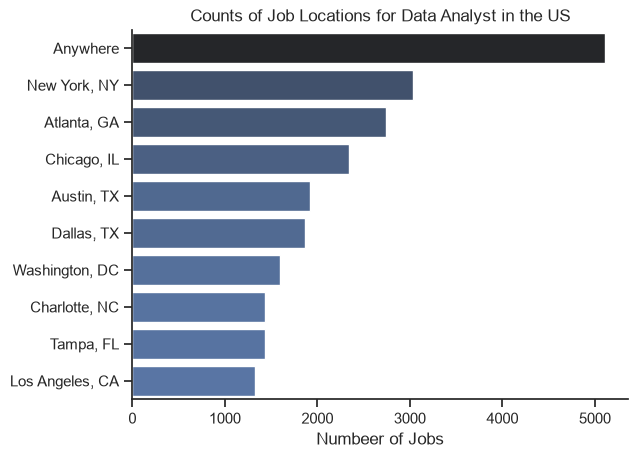

In [3]:
df_plot = df_DA_US['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data= df_plot, x='count', y='job_location', hue='count', palette='dark:b_r', legend= False)
sns.despine()
plt.title('Counts of Job Locations for Data Analyst in the US')
plt.xlabel('Numbeer of Jobs')
plt.ylabel('')
plt.show()

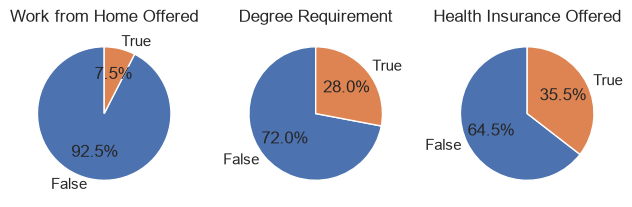

In [4]:
fig, ax = plt.subplots(1, 3)

dict_column = {
    'job_work_from_home': 'Work from Home Offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health Insurance Offered'
}

for i, (column, title) in enumerate(dict_column.items()):

    ax[i].pie(
        df_DA_US[column].value_counts(),
        startangle=90,
        autopct='%1.1f%%',
        labels=['False', 'True']
    )

    ax[i].set_title(title)

plt.tight_layout()
plt.show()

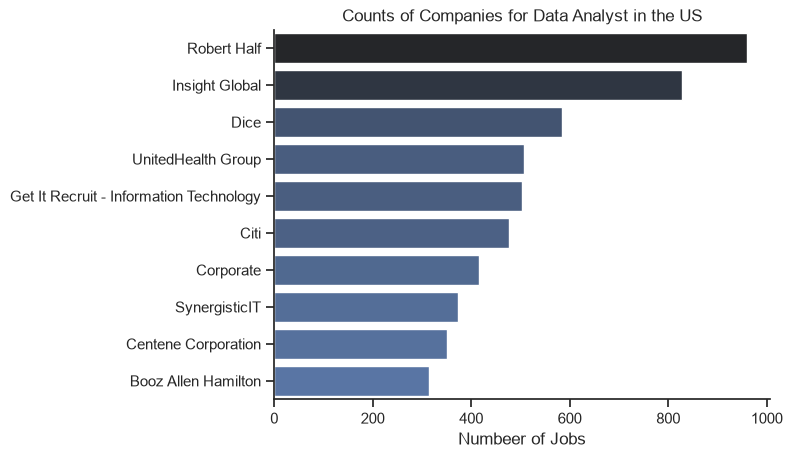

In [5]:
df_plot = df_DA_US['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data= df_plot, x='count', y='company_name', hue='count', palette='dark:b_r', legend= False)
sns.despine()
plt.title('Counts of Companies for Data Analyst in the US')
plt.xlabel('Numbeer of Jobs')
plt.ylabel('')
plt.show()